# End-to-end pipeline: six customers, one campaign

This notebook drives the same modules as `make all` (`src/atomiq/stage1.py`, `stage2.py`, `stage3.py`) and then checks the six root result files against each other.

Set `RUN_PIPELINE = True` to recompute everything from the organisers' data (about 5 minutes). With `False` it loads the committed result files, which CI regenerates and verifies on every push.

In [1]:
import os, sys, json, subprocess
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
os.chdir(ROOT)
RUN_PIPELINE = os.environ.get("RUN_PIPELINE", "0") == "1"
print("repo:", ROOT, "| run pipeline:", RUN_PIPELINE)

repo: /Users/yasaswiparuchuri/atomiq | run pipeline: False


## Stages 1 to 3
Each stage reads only the previous stage's output file, so the IDs and probabilities flow through unchanged.

In [2]:
if RUN_PIPELINE:
    from atomiq import stage1, stage2, stage3
    stage1.main()   # nested CV, pre-registered rule, final fit -> stage1_predictions.csv
    stage2.main()   # presolve, Dicke + XY QAOA, brute force, noisy run -> stage2_selection.*
    stage3.main()   # RY circuit, exact, Monte Carlo, noise, mitigation -> stage3_simulation.*

## Stage 1: predictions and the model-selection decision

In [3]:
import pandas as pd
s1 = json.loads((ROOT / "results/stage1_summary.json").read_text())
print("shipped:", s1["shipped_model"], "| final hyperparameters:", s1["final_hyperparameters"])
display(pd.read_csv(ROOT / "results/stage1_cv_summary.csv", header=[0, 1], index_col=0).xs("mean", axis=1, level=1).drop(columns="fold").round(4))
pd.read_csv(ROOT / "stage1_predictions.csv").head(12)

shipped: Hybrid | final hyperparameters: {'lr_C': 0.03, 'quantum_cfg': ['PQK', 0.1, 0.1, 0.1], 'w': 0.1}


,roc_auc,pr_auc,brier,log_loss,precision_at_k,recall_at_k
model,,,,,,
prior,0.5000,0.1167,0.1031,0.3602,0.1767,0.1514
LR,0.6507,0.3322,0.0965,0.3404,0.2767,0.2371
GBM,0.5423,0.2579,0.1098,0.4102,0.2500,0.2143
QK,0.5102,0.2270,0.1033,0.3626,0.1800,0.1543
PQK,0.4974,0.1841,0.1046,0.3687,0.1467,0.1257
Hybrid,0.6494,0.3302,0.0976,0.3435,0.2767,0.2371


,customer_id,predicted_probability,rank,is_top_10
0,C0031,0.487608,1,1
1,C0081,0.349708,2,1
2,C0079,0.292533,3,1
3,C0183,0.206932,4,1
4,C0087,0.193153,5,1
5,C0318,0.163473,6,1
6,C0265,0.159482,7,1
7,C0397,0.156573,8,1
8,C0359,0.154336,9,1
9,C0374,0.152741,10,1


## Stage 2: the six customers

In [4]:
s2 = json.loads((ROOT / "stage2_selection.json").read_text())
print("selected:", s2["selected_ids"])
print("objective %.4f | brute-force optimum %.4f | gap %.2e" % (s2["objective_value"], s2["brute_force_optimal_objective"], s2["optimality_gap"]))
print("best sampled bitstring (qubit 0 on the right):", s2["selected_bitstring_qiskit_order"])
display(pd.DataFrame(s2["depth_sweep"]).drop(columns=["params", "energy", "n_evals"], errors="ignore").round(4))
pd.read_csv(ROOT / "stage2_selection.csv")

selected: ['C0031', 'C0081', 'C0079', 'C0087', 'C0397', 'C0374']
objective 18.2972 | brute-force optimum 18.2972 | gap 0.00e+00
best sampled bitstring (qubit 0 on the right): 1010010111


,p,ansatz,p_feasible,p_hamming_weight_6,p_optimal,expected_objective_feasible_only,approx_ratio
0,0,Dicke only (uniform over 210),1.0,1.0,0.0048,12.2736,0.6708
1,1,Dicke + XY ring,1.0,1.0,0.0609,15.4716,0.8456
2,2,Dicke + XY ring,1.0,1.0,0.0818,15.6325,0.8544
3,3,Dicke + XY ring,1.0,1.0,0.1273,16.0943,0.8796


,qubit,customer_id,rank,predicted_probability,expected_deposit_value,contact_cost,capacity_units,expected_net_value,selected,brute_force_selected
0,0,C0031,1,0.487608,13,2,1,4.338900,1,1
1,1,C0081,2,0.349708,17,4,1,1.945029,1,1
2,2,C0079,3,0.292533,24,3,3,4.020804,1,1
3,3,C0183,4,0.206932,14,2,3,0.897047,0,0
4,4,C0087,5,0.193153,18,1,1,2.476760,1,1
5,5,C0318,6,0.163473,21,3,3,0.432932,0,0
6,6,C0265,7,0.159482,23,4,4,-0.331923,0,0
7,7,C0397,8,0.156573,30,1,3,3.697190,1,1
8,8,C0359,9,0.154336,14,1,2,1.160700,0,0
9,9,C0374,10,0.152741,25,2,1,1.818524,1,1


## Stage 3: P(at least 3 of 6 subscribe)

In [5]:
s3 = json.loads((ROOT / "stage3_simulation.json").read_text())
print(s3["circuit"]["qasm_free_description"])
pd.DataFrame(s3["results"])[["method", "backend", "shots", "p_ge3", "abs_error_vs_exact"]]

         ┌───────────┐  ░ ┌─┐               
   q_0: ─┤ Ry(1.546) ├──░─┤M├───────────────
         ├───────────┴┐ ░ └╥┘┌─┐            
   q_1: ─┤ Ry(1.2655) ├─░──╫─┤M├────────────
         ├────────────┤ ░  ║ └╥┘┌─┐         
   q_2: ─┤ Ry(1.1429) ├─░──╫──╫─┤M├─────────
        ┌┴────────────┤ ░  ║  ║ └╥┘┌─┐      
   q_3: ┤ Ry(0.91007) ├─░──╫──╫──╫─┤M├──────
        ├─────────────┤ ░  ║  ║  ║ └╥┘┌─┐   
   q_4: ┤ Ry(0.81364) ├─░──╫──╫──╫──╫─┤M├───
        ├─────────────┤ ░  ║  ║  ║  ║ └╥┘┌─┐
   q_5: ┤ Ry(0.80305) ├─░──╫──╫──╫──╫──╫─┤M├
        └─────────────┘ ░  ║  ║  ║  ║  ║ └╥┘
meas: 6/═══════════════════╩══╩══╩══╩══╩══╩═
                           0  1  2  3  4  5 


,method,backend,shots,p_ge3,abs_error_vs_exact
0,exact_poisson_binomial,classical,0,0.196908,0.000000e+00
1,statevector_ideal,qiskit.quantum_info.Statevector,0,0.196908,5.551115e-17
2,aer_ideal_finite_shots,AerSimulator (noiseless),200000,0.197105,1.970034e-04
3,monte_carlo_classical,numpy,1000000,0.196603,3.049966e-04
4,aer_noisy_unmitigated,AerSimulator.from_backend(FakeKingston),20000,0.199950,3.042003e-03
5,aer_noisy_readout_mitigated,FakeKingston + tensored readout inversion,20000,0.197245,3.373753e-04
6,aer_noisy_m3_mitigated,FakeKingston + mthree,20000,0.197321,4.134481e-04


## Figures

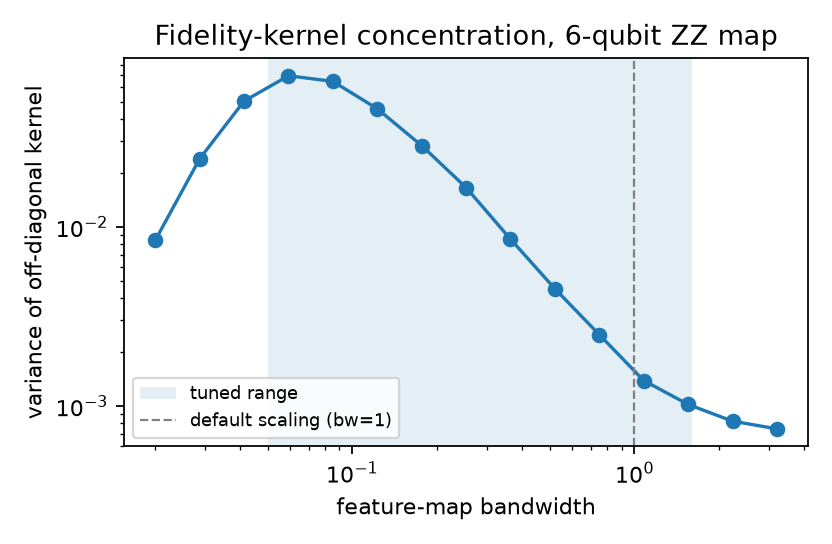

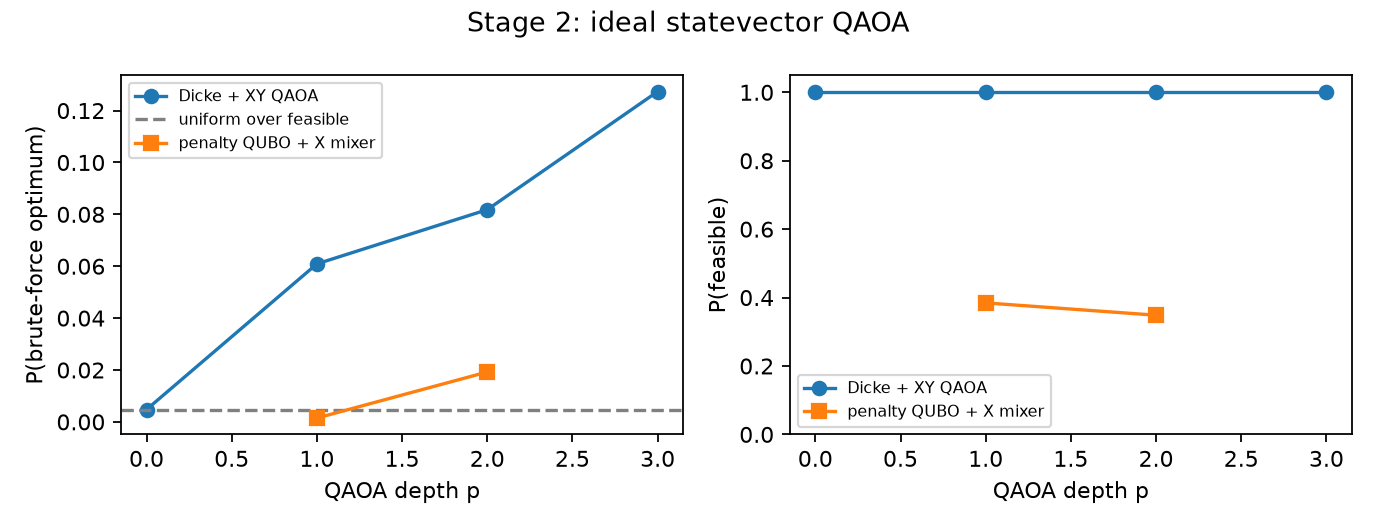

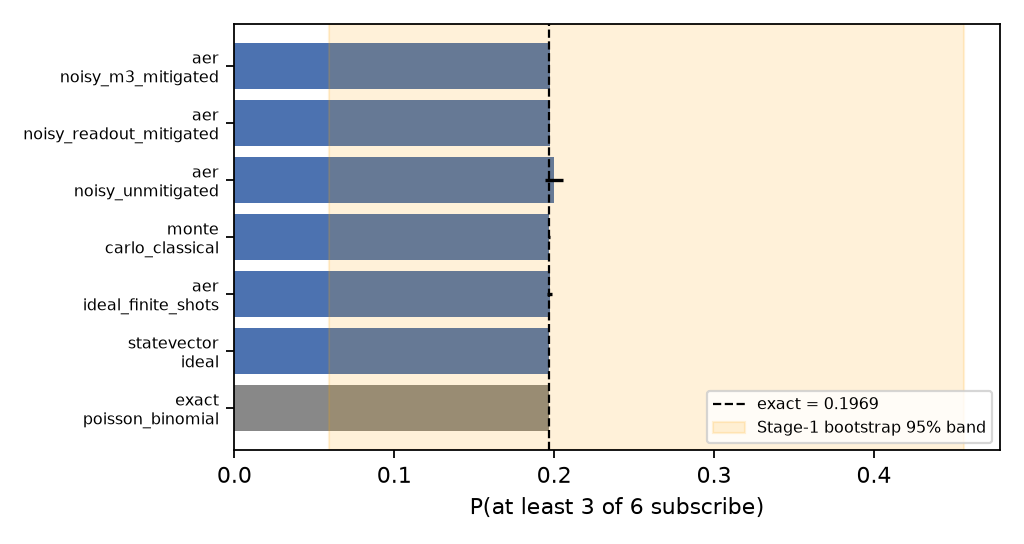

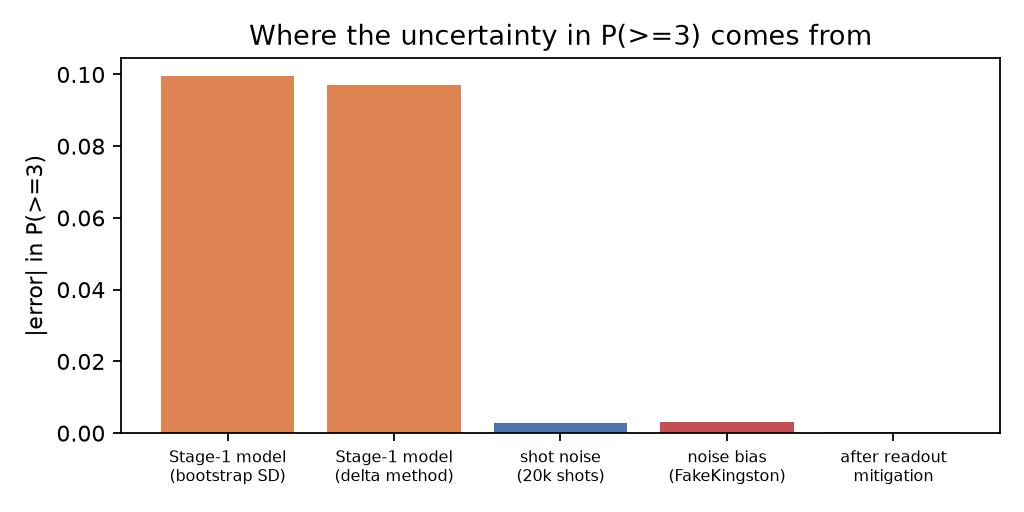

In [6]:
from IPython.display import Image, display
for f in ["stage1_kernel_concentration", "stage2_qaoa_depth", "stage3_estimates", "stage3_error_budget"]:
    display(Image(filename=str(ROOT / f"figures/{f}.png"), width=640))

## Cross-stage consistency check
The same 25 checks CI runs: file names, schemas, IDs flowing through, constraints, objective and exact P(≥3) recomputed from Stage 1.

In [7]:
out = subprocess.run([sys.executable, "scripts/check_submission.py"], capture_output=True, text=True, cwd=ROOT)
print(out.stdout[-1500:])
assert out.returncode == 0, out.stderr

PASS stage1_predictions.csv at repo root
PASS stage2_selection.csv at repo root
PASS stage2_selection.json at repo root
PASS stage3_simulation.csv at repo root
PASS stage3_simulation.json at repo root
PASS README.md at repo root
PASS LICENSE at repo root
PASS requirements.txt at repo root
PASS PREREGISTRATION.md at repo root
PASS stage1 columns
PASS stage1 has exactly the 100 test customers
PASS stage1 probabilities in [0,1]
PASS stage1 rank follows probability with customer_id tie-break
PASS stage1 top-10 flag
PASS stage2 candidates == stage1 top 10 (same order)
PASS stage2 selects 6 unique IDs from the top 10
PASS budget 13 <= 25
PASS capacity 10 <= 22
PASS stage2 objective recomputes from stage1 probabilities
PASS optimality gap = 0
PASS stage3 uses the stage2 selection
PASS stage3 input probabilities == stage1 probabilities
PASS stage3 exact value recomputes
PASS stage3 quantum estimate within 4 SE of exact
PASS stage3 csv columns

All checks passed.

